In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_dataset.csv")
print("Shape:", df.shape)
print()
df.info()
print()
print("Nulls per column:")
print(df.isnull().sum())
df.head()

Shape: (1000, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Nulls per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [9]:
# Convert Date from text to a real date
df["Date"] = pd.to_datetime(df["Date"])

num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

stats = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": df[num_cols].mode().iloc[0],
    "Std Dev": df[num_cols].std()
})
print(stats.round(2))

                  Mean  Median  Mode  Std Dev
Age              41.39    42.0  43.0    13.68
Quantity          2.51     3.0   4.0     1.13
Price per Unit  179.89    50.0  50.0   189.68
Total Amount    456.00   135.0  50.0   560.00


**Observations (descriptive statistics):**
- The average customer age is about 41 (median 42), so customers are spread fairly evenly around the middle-aged range.
- Customers usually buy 2-3 items per order (average 2.5).
- The average Price per Unit (179.89) is much higher than the median (50). A few expensive items pull the average up, and most items are cheap.
- The same pattern shows in Total Amount: the average order is 456, but the median is only 135. A small number of large orders drive the average, so the median describes a typical order better.

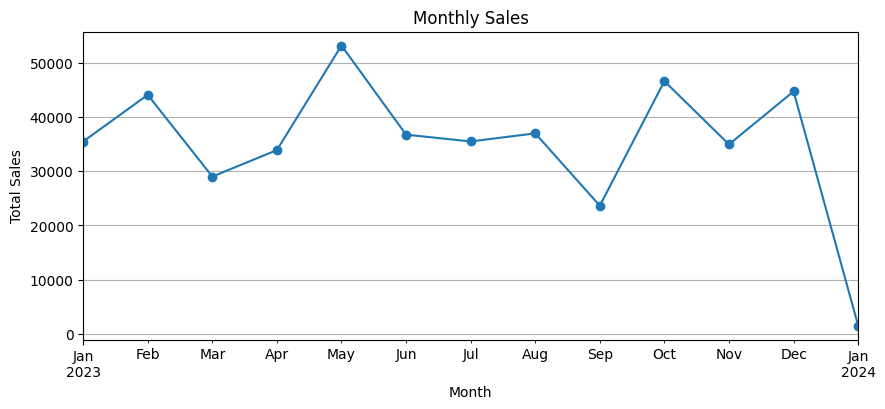

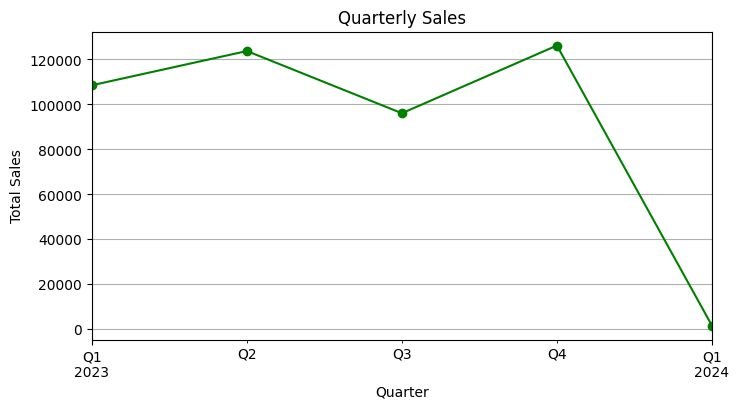

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64
Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


In [10]:
# Monthly sales
monthly = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum()
plt.figure(figsize=(10, 4))
monthly.plot(marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

# Quarterly sales
quarterly = df.groupby(df["Date"].dt.to_period("Q"))["Total Amount"].sum()
plt.figure(figsize=(8, 4))
quarterly.plot(marker="o", color="green")
plt.title("Quarterly Sales")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

print(monthly)
print(quarterly)

*Observations (sales trends):**
- Sales were highest in May 2023 (53,150) and lowest in September 2023 (23,620). Other peaks were October (46,580), February (44,060) and December (44,690).
- By quarter, Q4 2023 was the strongest (126,190), followed by Q2 (123,735). Q3 was the weakest (96,045).
- The January 2024 figure (1,530) is very small because the dataset only includes the first days of that month, so it is not a real drop in sales and is excluded from the trend conclusions.


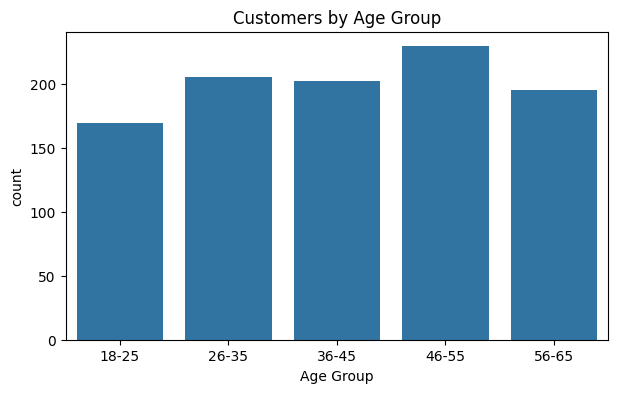

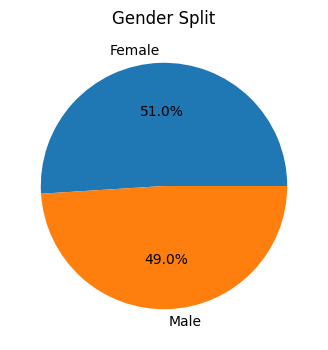

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195
Name: count, dtype: int64
Gender
Female    510
Male      490
Name: count, dtype: int64


In [11]:
# Age groups
bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Age Group")
plt.title("Customers by Age Group")
plt.show()

# Gender breakdown
plt.figure(figsize=(4, 4))
df["Gender"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Gender Split")
plt.ylabel("")
plt.show()

print(df["Age Group"].value_counts().sort_index())
print(df["Gender"].value_counts())

**Observations (customer demographics):**
- Customers are spread fairly evenly across age groups. The largest group is 46-55 (229 customers) and the smallest is 18-25 (169), so no single age group dominates.
- The gender split is almost equal: 510 female (51%) and 490 male (49%).
- Because the customer base is balanced, marketing doesn't need to target only one age group or gender. Differences in spending between groups are a better thing to look at next.

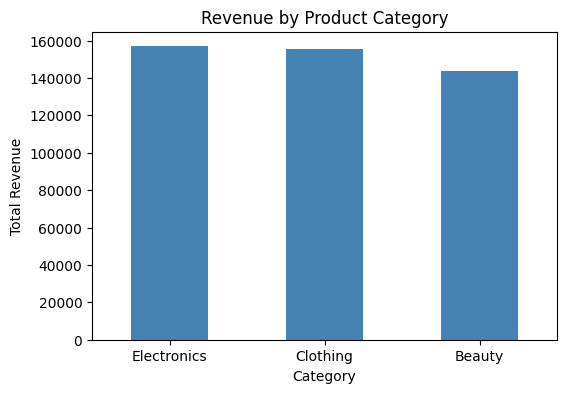

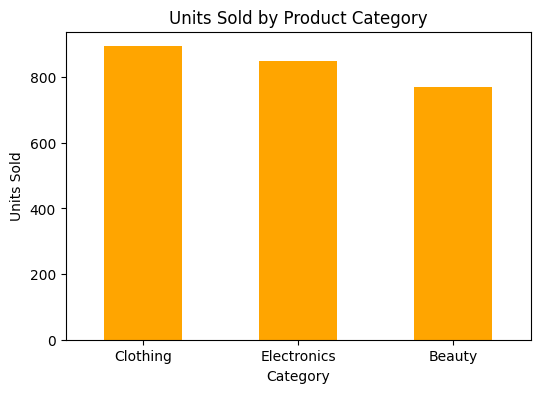

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64
Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


In [12]:
# Revenue by product category
revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(6, 4))
revenue.plot(kind="bar", color="steelblue")
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.show()

# Units sold by category (best sellers by volume)
units = df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)
plt.figure(figsize=(6, 4))
units.plot(kind="bar", color="orange")
plt.title("Units Sold by Product Category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=0)
plt.show()

print(revenue)
print(units)

**Observations (product analysis):**
- Electronics earned the most revenue (156,905), followed closely by Clothing (155,580) and Beauty (143,515).
- Clothing sold the most units (894), so Electronics earns more per item because it costs more.
- The dataset has product categories, not individual products, so the analysis is done by category.

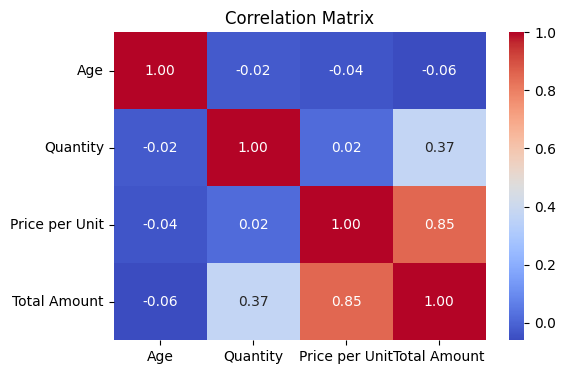

                 Age  Quantity  Price per Unit  Total Amount
Age             1.00     -0.02           -0.04         -0.06
Quantity       -0.02      1.00            0.02          0.37
Price per Unit -0.04      0.02            1.00          0.85
Total Amount   -0.06      0.37            0.85          1.00


In [13]:
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

print(corr.round(2))

**Observations (correlation):**
- Total Amount is strongly linked to Price per Unit (0.85) and moderately linked to Quantity (0.37). The price of the item matters more than how many items are bought.
- Age has almost no correlation with any other variable, so a customer's age does not predict how much they spend.

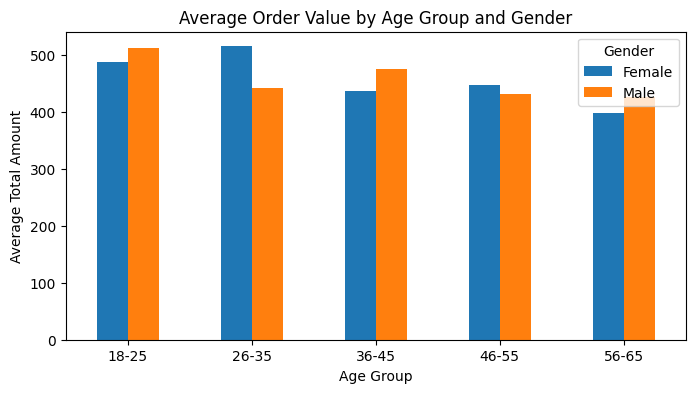

Gender     Female   Male
Age Group               
18-25       487.0  512.0
26-35       515.0  442.0
36-45       437.0  475.0
46-55       448.0  431.0
56-65       398.0  426.0


In [14]:
avg = df.groupby(["Age Group", "Gender"], observed=True)["Total Amount"].mean().unstack()

avg.plot(kind="bar", figsize=(8, 4))
plt.title("Average Order Value by Age Group and Gender")
plt.xlabel("Age Group")
plt.ylabel("Average Total Amount")
plt.xticks(rotation=0)
plt.show()

print(avg.round(0))

**Observations (average order value by age and gender):**
- Average spending is similar across all groups (roughly 400-515). Women aged 26-35 (515) and men aged 18-25 (512) spend slightly more, and women aged 56-65 spend the least (398).
- The differences are small, so age and gender are not strong predictors of spending. This matches the low correlation for Age found earlier.

## Conclusion and Recommendations

1. **Plan around seasonality.** Sales peaked in May and Q4 2023 and were lowest in September. Stock up and run promotions before Q4 and May, and use offers to lift the slow September period.
2. **Focus on higher-priced items.** Price per unit drives total sales (correlation 0.85) much more than quantity (0.37). Electronics earned the most revenue, so promote Electronics and upsell to higher-priced items instead of trying to sell more units of cheap ones.
3. **Use broad marketing instead of narrow targeting.** Customers are spread evenly across age groups and genders, and their spending is similar. Campaigns should aim at everyone, and small tests could be run on the slightly higher-spending groups (women 26-35, men 18-25).

*Limitations: the dataset has 1,000 transactions covering one year, and January 2024 is incomplete, so these findings should be tested on more data.*